<a href="https://colab.research.google.com/github/Dimas-091206/pm-turi4-clustering-dimasfaturohman/blob/main/PM_P9_Dimas_Faturohman_2488010003.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1: Menyiapkan Data & Scaling

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
df = pd.DataFrame({
    'usia': [19, 21, 20, 23, 22, 45, 50, 48, 52, 46, 25, 28, 22, 24, 29, 55, 60, 58, 62, 57],
    'pendapatan': [15, 18, 12, 20, 16, 75, 80, 85, 90, 78, 30, 35, 28, 32, 40, 22, 25, 20, 24, 21],
    'skor_belanja': [85, 90, 78, 88, 92, 20, 15, 25, 18, 22, 50, 55, 60, 48, 52, 10, 12, 15, 8, 14]
})
X_scaled = StandardScaler().fit_transform(df)

Langkah 2: Metode Elbow Menentukan K

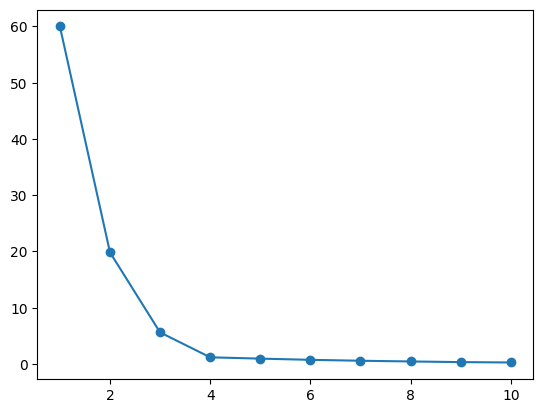

In [2]:
from sklearn.cluster import KMeans
inertias = []
for k in range (1, 11):
  km = KMeans (n_clusters=k, random_state=42, n_init=10)
  km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1, 11), inertias, marker='o'); plt.show()

Langkah 3: Menjalankan K-Means (K=3)

In [3]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
2    10
0     5
1     5
Name: count, dtype: int64


Langkah 4: Evaluasi silhouette score

In [4]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.7690010837157963


Langkah 5: Interpretasi: Profil rata-rata tiap cluster

In [5]:
profil = df.groupby('cluster')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1)
print(profil)

         usia  pendapatan  skor_belanja
cluster                                
0        48.2        81.6          20.0
1        58.4        22.4          11.8
2        23.3        24.6          69.8


D. Latihan Mandiri

6. Jalankan K-Means K=5; Bandingkan silhouette score dengan K=3

In [6]:
kmeans_k5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster_k5'] = kmeans_k5.fit_predict(X_scaled)
print(df['cluster_k5'].value_counts())
score_k5 = silhouette_score(X_scaled, df['cluster_k5'])
score_k3 = silhouette_score(X_scaled, df['cluster'])


print("\n--- Perbandingan Silhouette Score ---")
print(f"Silhouette Score (K=3) : {score_k3:.4f}")
print(f"Silhouette Score (K=5) : {score_k5:.4f}")

cluster_k5
0    5
2    5
3    5
4    3
1    2
Name: count, dtype: int64

--- Perbandingan Silhouette Score ---
Silhouette Score (K=3) : 0.7690
Silhouette Score (K=5) : 0.6677


7. Jalankan K-Means tanpa scaling (K=3); Bandingkan silhoutte-nya. apa kesimpulannya?

In [7]:
kmeans_no_scale = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_no_scale = kmeans_no_scale.fit_predict(df[['usia', 'pendapatan', 'skor_belanja']])
score_no_scale = silhouette_score(df[['usia', 'pendapatan', 'skor_belanja']], cluster_no_scale)

print("\n--- Perbandingan Silhouette Score ---")
print(f"Silhouette Score (K=3) : {score_k3:.4f}")
print(f"Silhouette Score (K=3 tanpa scaling) : {score_no_scale:.4f}")


--- Perbandingan Silhouette Score ---
Silhouette Score (K=3) : 0.7690
Silhouette Score (K=3 tanpa scaling) : 0.7398


8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y)

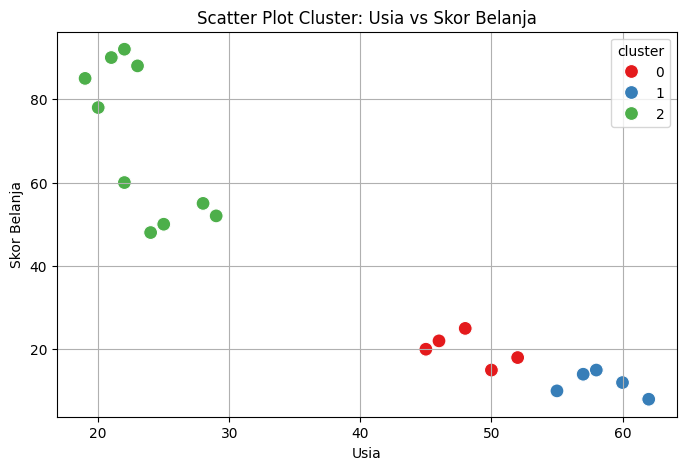

In [8]:
import seaborn as sbn
plt.figure(figsize=(8, 5))
sbn.scatterplot(data=df, x='usia', y='skor_belanja', hue='cluster', palette='Set1', s=100)
plt.title('Scatter Plot Cluster: Usia vs Skor Belanja')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.grid(True)
plt.show()

E. Refleksi

9. Bagaimana K-Means menemukan kelomok tanpa label?

Jawaban:

K-Means bekerja secara itertif berbasis jarak, Algoritma ini menepatkan K titik centroid secara acak, kemudian memasukkan setiap titik data ke cluster dengan centorid terdekat, kemudian menghitung ulang posisi setiapp centroid sebagai rata-rata/mean titik anggotanya, langkah ini diulang hingga centroid tidak berpindah lagi (konvergen)


10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?

Jawaban:

Karena pada kasus diatas, titik K=3 memberikan efesiensi penurunan inertia (WCSS) paling optimal penambahan nilai K dari 1-3 menekan total kuadrat jarak antar titik-titik centroidnya, setelah sampai pada K=3 penurunannya nilai inertia melandai dan tidak signifikan

11. Mengapa Scaling penting, dan apa dampaknya bila dilewatkan

Jawaban:

Scaling sangatlah penting dalam kasus diatas (nomor 7), ketika scaling tidak digunakan nilai silhoutte menjadi lebih kecil dan tidak optimal. disisi lain fitur dengan skala lebih besar akan mendominasi dibanding fitur yang skalanya lebih kecil (dalam kasus ini fitur pendapatan dan usia)